In [1]:
import numpy as np
rng = np.random.default_rng(20)

In [2]:
import plotnine as pn
from scipy import stats

In [3]:
pop_size = 55e4
overall_prevalence = 0.01
HH_attack_rate = 0.4
mean_HH_size = 2.1
mean_infected_per_HH = 1 + (mean_HH_size - 1) * HH_attack_rate
num_HH_infected = round((pop_size * overall_prevalence) / mean_infected_per_HH)
num_people_infected = round(pop_size * overall_prevalence)

In [4]:
HH_size = rng.poisson(mean_HH_size-1, round(pop_size / mean_HH_size)) + 1
actual_pop = sum(HH_size)
print(f"There are {len(HH_size)} households with total population {actual_pop}")

There are 261905 households with total population 551191


/home/joshuab/COVID/SEIR_prevalence/venv/lib/python3.6/site-packages/plotnine/stats/stat_bin.py:95: PlotnineWarning: 'stat_bin()' using 'bins = 176'. Pick better value with 'binwidth'.


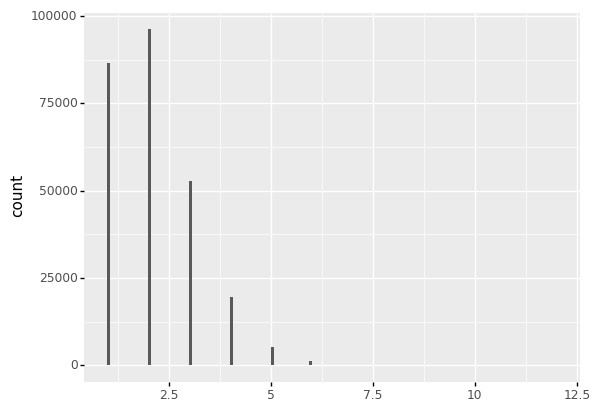

<ggplot: (8728613957738)>

In [41]:
pn.qplot(x=HH_size, geom="histogram")

In [42]:
num_inf_per_HH = np.zeros_like(HH_size)
total_infected = 0
i = 0
while total_infected < num_people_infected:
    num_inf_per_HH[i] = rng.binomial(HH_size[i] - 1, HH_attack_rate) + 1
    total_infected += num_inf_per_HH[i]
    i += 1
print(f"{total_infected} people are infected from {i} households, a prevalence of {total_infected/actual_pop}")

5501 people are infected from 3853 households, a prevalence of 0.00998020649829188


In [107]:
num_samples = 10_000

/home/joshuab/COVID/SEIR_prevalence/venv/lib/python3.6/site-packages/plotnine/stats/stat_bin.py:95: PlotnineWarning: 'stat_bin()' using 'bins = 40'. Pick better value with 'binwidth'.


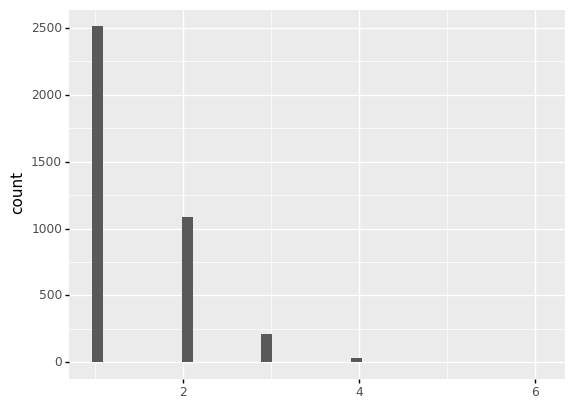

<ggplot: (8728614185992)>

In [122]:
pn.qplot(x=num_inf_per_HH[num_inf_per_HH != 0], geom="histogram")

In [123]:
n_sims = 1_000

In [124]:
pos_tests = np.zeros(n_sims)
total_tests = np.zeros(n_sims)
HH_order = np.arange(len(HH_size))
for i in range(n_sims):
    rng.shuffle(HH_order)
    j = 0
    while total_tests[i] < num_samples:
        HH_num = HH_order[j]
        pos_tests[i] += num_inf_per_HH[HH_num]
        total_tests[i] += HH_size[HH_num]
        j += 1
obs_prev = pos_tests / total_tests
print(f"An average of {pos_tests.mean()} of {total_tests.mean()} positive, {100*obs_prev.mean()}%")

An average of 99.553 of 10000.822 positive, 0.9954480951593179%


In [125]:
def rho(D, n):
    return (D - 1) / (n - 1)

def rho2(D, n):
    r = rho(D, n)
    return (1 - r)

def theta(D, n):
    r = rho(D, n)
    return r / (1 - r)

print(rho(1.71, 10_000))
print(rho(1.44, 100_000))
print(rho2(1.71, 10_000))
print(rho2(1.44, 100_000))
print(theta(1.71, 10_000))
print(theta(1.44, 100_000))

7.1007100710071e-05
4.400044000440004e-06
0.9999289928992899
0.9999955999559995
7.101214307646607e-05
4.4000633609123965e-06


In [126]:
obs_var = pos_tests.var()
obs_mean = pos_tests.mean()
sample_prev = pos_tests.sum() / total_tests.sum()
binomial_var = num_samples * sample_prev * (1 - sample_prev)
dispersion = obs_var / binomial_var
rho = (dispersion - 1) / (num_samples - 1)
print(f"An variance of {pos_tests.var()} positives, {obs_var} prevalence")
print(f"A binomial variable would have variance {binomial_var} meaning the dispersion is {dispersion}")

An variance of 172.183191 positives, 172.183191 prevalence
A binomial variable would have variance 98.55390034856977 meaning the dispersion is 1.7470966688382186


In [127]:
obs_var / (total_tests.sum() * sample_prev)

0.0017295630568641828

In [128]:
pi = sample_prev
alpha = (1 - rho) * pi / rho
beta = (1 - pi) * (1 - rho) / rho

In [129]:
(obs_var - 1) / (total_tests.sum() - obs_var)

1.711720679513014e-05

In [130]:
x = range(int(min(pos_tests)), int(max(pos_tests))+1)
betabinom_y = stats.betabinom(n=num_samples, a=alpha, b=beta).pmf(x)
binom_y = stats.binom(n=num_samples, p=pi).pmf(x)

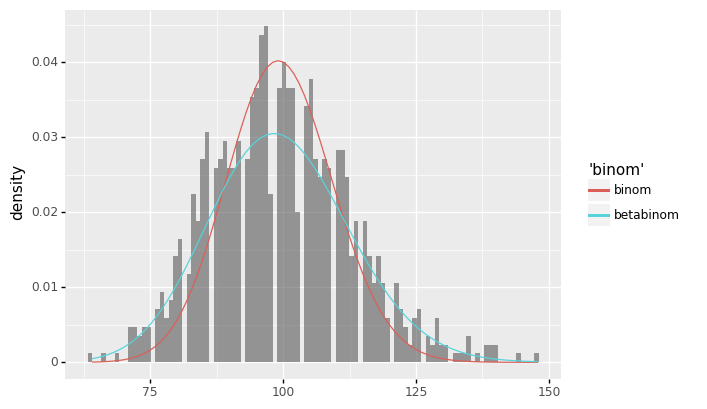

<ggplot: (8728605464573)>

In [131]:
(pn.ggplot(pn.aes(x=pos_tests)) +
 pn.geom_histogram(pn.aes(y="..density.."), bins=100, alpha = 0.6) +
 pn.geom_line(pn.aes(x=x, y=binom_y, colour="'binom'")) +
 pn.geom_line(pn.aes(x=x, y=betabinom_y, colour="'betabinom'"))
)

In [132]:
stats.betabinom(n=num_samples, a=alpha, b=beta).pmf(950)

7.445420485472693e-220

In [133]:
stats.binom(n=num_samples, p=overall_prevalence).pmf(900)

0.0

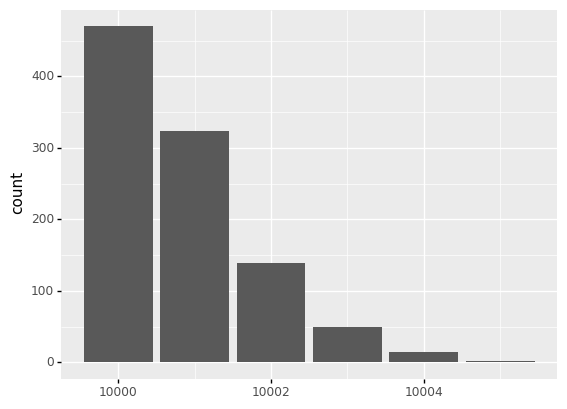

<ggplot: (-9223363308249606505)>

In [134]:
pn.qplot(x=total_tests, geom="bar")

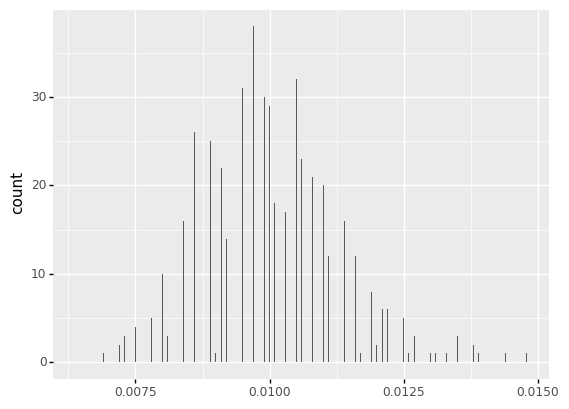

<ggplot: (-9223363308240594702)>

In [135]:
pn.qplot(x=obs_prev, geom="histogram", bins=1000)